# Proyecto estadísticas de YouTube Avances IV

**Semana 10 · 24 de octubre de 2026**

Cristian Camilo Alarcon Delgadillo · Bryan Arley Saenz Cortes · Jonathan David Lancheros Bello

Este notebook evalúa el artefacto congelado de Avances III y documenta resultados, retos y límites. La prueba de 374 videos ya se conocía en Avances II: se utiliza de forma retrospectiva, sin nueva selección. La separación por fecha de publicación es una prueba de estrés interna; no valida un pronóstico futuro.

[Repositorio](https://github.com/Camilo19P8/youtube-estadisticas-nlp) · Código desarrollado en VS Code.

La copia distribuida se verifica con Python local. El entorno de cada ejecución aparece en la primera salida; abrir el cuaderno en Colab permite repetirlo allí sin confundir ambos entornos.

In [1]:
import io, os, sys, urllib.request, zipfile, platform
from pathlib import Path
SOURCE_COMMIT = 'eb793a5282a6b6b5f20f1d67cf48fa965d928135'
url = f'https://codeload.github.com/Camilo19P8/youtube-estadisticas-nlp/zip/{SOURCE_COMMIT}'
archive = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
IS_COLAB = 'google.colab' in sys.modules
workdir = Path('/content/avances_iv') if IS_COLAB else Path.cwd() / '.execution'
workdir.mkdir(exist_ok=True)
archive.extractall(workdir)
repo = workdir / archive.namelist()[0].split('/')[0]
os.chdir(repo)
sys.path.insert(0, str(repo))
print('Código fuente fijado:', SOURCE_COMMIT)
print('Entorno:', 'Google Colab' if IS_COLAB else 'Python local')
print('Python:', platform.python_version())
import runpy
_download = runpy.run_path('download_data.py', run_name='__main__')

Código fuente fijado: eb793a5282a6b6b5f20f1d67cf48fa965d928135
Entorno: Python local
Python: 3.12.14


comments.csv bc78f5fbddcf57cfcde8609ce35a23658c2eb98fca05d1ffe62fff65a20f651b VERIFICADO
videos-stats.csv 09b52f4ac493ffb7a07e64eca489c31afd43cc540398bf626988eaa3cebf930a VERIFICADO


## Protocolo final

Se conserva el modelo elegido en Avances III. La referencia HGB se ajusta solo con los 1.493 videos de desarrollo. Se calculan RMSE, MAE y R² en escala log y errores en vistas originales. El bootstrap mantiene predicciones fijas. No se hace una búsqueda de hiperparámetros con la prueba conocida.

In [2]:
from final_evaluation import evaluate_final
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=2):
    summary_iv = evaluate_final()

EVALUACION FINAL COMPLETADA
                         model     rmse      mae        r2    mae_views   rmse_views
        Ensamble congelado III 0.559311 0.421376  0.946111 1.133441e+07 1.743325e+08
Solo comentarios congelado III 2.101733 1.681654  0.239063 1.778423e+07 2.138673e+08
             HGB referencia II 0.583084 0.441142  0.941433 1.325738e+07 1.952832e+08
                       Mediana 2.416824 1.966001 -0.006199 1.796334e+07 2.139382e+08

ESTRES POR PUBLICACION
              model     rmse      mae        r2    mae_views   rmse_views
           HGB fijo 0.702289 0.545331  0.825805 4.775931e+05 4.195750e+06
      Ensamble fijo 0.749735 0.597131  0.801473 6.195421e+05 6.379602e+06
Texto fijo alpha 10 3.310044 2.989860 -2.869654 1.166825e+06 3.126922e+06

VERIFICACIONES {"parity_cases": 50, "max_error_log": 3.552713678800501e-15, "tolerance": 1e-08, "invalid_inputs_rejected": 6, "invalid_inputs_tested": 6, "latency_ms_median": 5.95095002790913, "latency_ms_p95": 10.664614956476

In [3]:
import pandas as pd, json, numpy as np
from IPython.display import display
print('EVALUACIÓN RETROSPECTIVA: prueba conocida, no externa')
retrospective = pd.read_csv('results_iv/retrospective_metrics.csv')
display(retrospective.round(5))
print('ESTRÉS POR FECHA DE PUBLICACIÓN')
display(pd.read_csv('results_iv/publication_stress.csv').round(5))
print('VERIFICACIONES DE SOFTWARE')
display(pd.Series(json.loads(Path('results_iv/verification.json').read_text())))

EVALUACIÓN RETROSPECTIVA: prueba conocida, no externa


,model,rmse,mae,r2,mae_views,rmse_views
0,Ensamble congelado III,0.55931,0.42138,0.94611,1.133441e+07,1.743325e+08
1,Solo comentarios congelado III,2.10173,1.68165,0.23906,1.778423e+07,2.138673e+08
2,HGB referencia II,0.58308,0.44114,0.94143,1.325738e+07,1.952832e+08
3,Mediana,2.41682,1.96600,-0.00620,1.796334e+07,2.139382e+08


ESTRÉS POR FECHA DE PUBLICACIÓN


,model,rmse,mae,r2,mae_views,rmse_views
0,HGB fijo,0.70229,0.54533,0.82580,4.775931e+05,4.195750e+06
1,Ensamble fijo,0.74974,0.59713,0.80147,6.195421e+05,6.379602e+06
2,Texto fijo alpha 10,3.31004,2.98986,-2.86965,1.166825e+06,3.126922e+06


VERIFICACIONES DE SOFTWARE


parity_cases                      50
max_error_log                    0.0
tolerance                        0.0
invalid_inputs_rejected            6
invalid_inputs_tested              6
latency_ms_median            5.95095
latency_ms_p95             10.664615
passed                          True
dtype: object

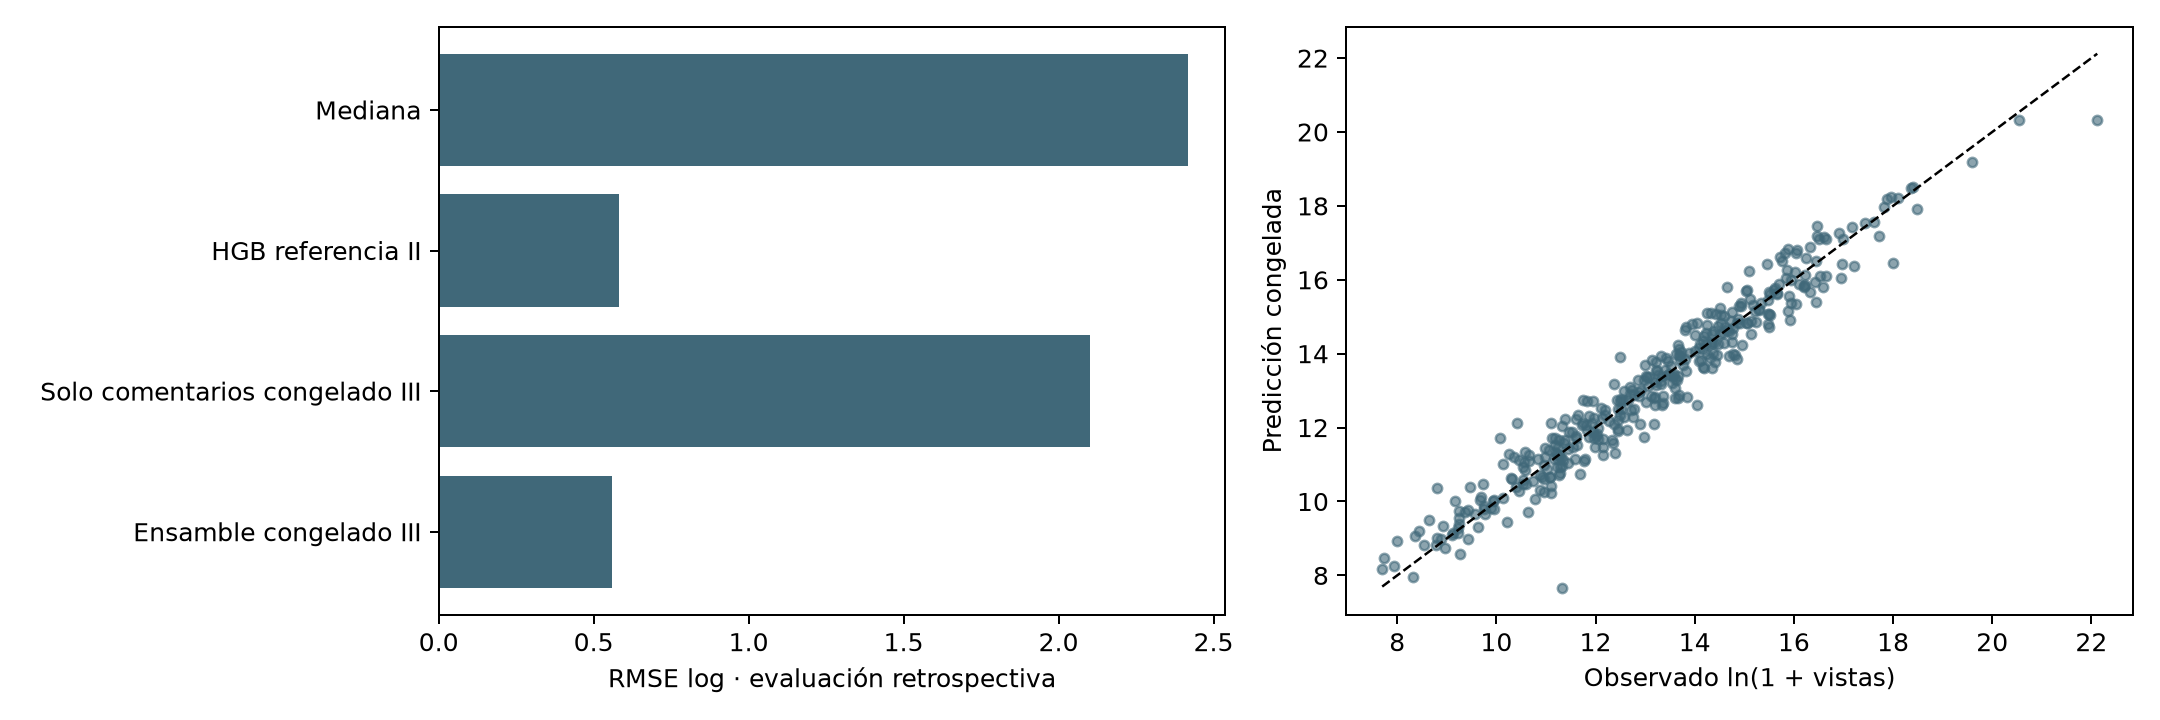

In [4]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(retrospective['model'], retrospective['rmse'], color='#406879')
axes[0].set_xlabel('RMSE log · evaluación retrospectiva')
pred = pd.read_csv('results_iv/retrospective_predictions.csv')
axes[1].scatter(pred.observed_log, pred.prediction_log, s=14, alpha=.6, color='#406879')
limits = [pred.observed_log.min(), pred.observed_log.max()]
axes[1].plot(limits, limits, 'k--', linewidth=1)
axes[1].set(xlabel='Observado ln(1 + vistas)', ylabel='Predicción congelada')
fig.tight_layout()
fig.savefig('results_iv/final_comparison.png', dpi=180)
from IPython.display import Image as NotebookImage
display(NotebookImage(filename='results_iv/final_comparison.png'))
plt.close(fig)

## Interpretación y reproducción

Los comentarios aislados, las interacciones y el ensamble responden a entradas distintas. La precisión contemporánea no demuestra capacidad para anticipar vistas a siete o treinta días. Se necesitan canal, fecha de captura y observaciones posteriores para esa validación. La inferencia portable comprueba equivalencia numérica y validación de entradas; no es una nueva muestra predictiva.

El historial de GitHub documenta revisiones de esta cuenta; no se usa para atribuir aportes a otros integrantes. La evidencia colaborativa se distingue de los artefactos técnicos.

In [5]:
import shutil
export_base = Path('/content/resultados_avances_iv') if IS_COLAB else repo.parent / 'resultados_avances_iv'
shutil.make_archive(str(export_base), 'zip', 'results_iv')
print('Resultados guardados en', str(export_base) + '.zip')

Resultados guardados en C:\Users\calar\Documents\Codex\2026-10-18\pued\work\avances_iv\repo\.execution\resultados_avances_iv.zip
